# CSE 438 - Assignment 02
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | Full Comparison Notebook |
| **Assignment 01 Decoder** | Segformer |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 18 Augest 2026 |

# Full Comparison Analysis

### Label-Efficient Self-Supervised Learning vs. Fully Supervised Segmentation

**Research question:** *Can self-supervised learning (SSL) achieve competitive segmentation
performance using dramatically fewer labelled images than a fully supervised SegFormer baseline?*

This notebook does **not** retrain any model. It loads the already-computed results produced by
five prior experiment notebooks and assembles a single, publication-quality comparison:

| # | Notebook | Role |
|---|---|---|
| 1 | `SegFormer-B0` | Fully supervised baseline (Part-A) |
| 2 | `MAE` | SSL pretraining + supervised fine-tuning |
| 3 | `BYOL` | SSL pretraining + supervised fine-tuning |
| 4 | `DINOv2` | SSL pretraining + supervised fine-tuning |
| 5 | `SimCLR` | SSL pretraining + supervised fine-tuning |

> **Data-integrity note (read before trusting any number below):** the source MAE and BYOL
> notebooks supplied for this comparison had **no executed cell outputs** — every output cell was
> empty when inspected. This notebook therefore cannot report real MAE/BYOL test metrics unless
> their Kaggle result artifacts (a `results/mae/...` or `results/byol/...` folder, zipped) are
> attached as additional inputs. DINOv2 and SimCLR **did** contain executed outputs with genuine
> numeric results, which are used directly below. This is stated explicitly, rather than
> silently inventing numbers, throughout the notebook (Section 4 and the provenance table in
> Section 18 record exactly what was found and what is missing).

## 1. Objective

Compare **Test mIoU** (the primary segmentation metric) across:

- **SegFormer-B0** — fully supervised, trained on the full labelled Part-A training split
- **MAE**, **BYOL**, **DINOv2**, **SimCLR** — self-supervised pretraining on unlabelled images,
  followed by supervised segmentation fine-tuning on a **much smaller labelled split**

The central research story has two independent axes that must never be conflated:

1. **Total images used for SSL pretraining** (unlabelled — large, e.g. 10,526 images)
2. **Labelled images required for the supervised fine-tuning / training step** (small for SSL
   methods, large for the fully supervised baseline)

The label-efficiency claim concerns axis (2) only. SSL methods still consume a large number of
*unlabelled* images during pretraining — this notebook keeps that distinction explicit
everywhere a count is shown.

## 2. Configuration & Reproducibility

Kaggle-friendly relative paths. Attach the following as Kaggle **input datasets** (or leave
absent — the notebook detects what is available and reports what is missing rather than
fabricating values):

- The **SegFormer output ZIP** (from `nb2-segformer-b0.ipynb`'s Part-2 output directory)
- The **DINOv2** results folder/ZIP (`results/dinov2/...`)
- The **SimCLR** results folder/ZIP (`results/simclr/...`)
- Optionally, **MAE** and **BYOL** results folders/ZIPs, if those notebooks were subsequently run
  to completion — this notebook will pick them up automatically if present.

In [1]:
import os
import json
import glob
import shutil
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import gridspec
from IPython.display import display, Markdown, Image as IPImage

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Path(s) to search for the SegFormer output. Accepts a .zip file OR an
# already-extracted directory. Edit this to point at your attached Kaggle
# input, e.g. "/kaggle/input/segformer-result2-part2/segformer-result2-part2.zip"
SEGFORMER_ZIP_PATH = "/kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results"

# SSL method result locations (zip OR directory). The notebook searches
# broadly under /kaggle/input/ as a fallback if these exact paths don't exist.
SSL_ZIP_PATHS = {
    "MAE":    "/kaggle/input/datasets/nasrullahsijan/maeoutput/results",
    "BYOL":   "/kaggle/input/datasets/nasrullahsijan/boyloutput/results",
    "DINOv2": "/kaggle/input/datasets/nasrullahsijan/dinov2output/results",
    "SimCLR": "/kaggle/input/datasets/nasrullahsijan/simclroutput/results",
}

WORKDIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./working")
EXTRACT_DIR = WORKDIR / "extracted_artifacts"
OUTPUT_DIR = WORKDIR / "comparison_outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
for d in (EXTRACT_DIR, OUTPUT_DIR, FIGURES_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------
# PLOTTING CONFIGURATION -- consistent visual identity
# ----------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.frameon": False,
})

# One consistent color per method across every figure in this notebook.
# SegFormer (the fully supervised baseline) gets a distinct, muted color;
# SSL methods share a coordinated palette so the baseline always stands out.
METHOD_COLORS = {
    "SegFormer": "#4C4C4C",   # baseline -- neutral dark grey, visually distinct
    "MAE":       "#4C72B0",
    "BYOL":      "#55A868",
    "DINOv2":    "#C44E52",
    "SimCLR":    "#8172B2",
}
METHOD_ORDER = ["SegFormer", "MAE", "BYOL", "DINOv2", "SimCLR"]

print("Configuration loaded.")
print(f"Working directory : {WORKDIR.resolve()}")
print(f"Output directory  : {OUTPUT_DIR.resolve()}")

Configuration loaded.
Working directory : /kaggle/working
Output directory  : /kaggle/working/comparison_outputs


## 3. Experiment Overview & Protocol Diagram

Both experimental branches share the **same dataset, the same 3-way split, and the same
binary Clear/Contaminated segmentation task**. They differ only in how the labelled data is
used:

- **Fully supervised branch:** SegFormer-B0 is trained directly on the full labelled training
  split.
- **SSL branch:** each method first pretrains an encoder on the training split **with no
  segmentation labels at all**, then a segmentation head is fine-tuned using only the much
  smaller labelled validation split.

Both branches are evaluated on the same held-out test split.

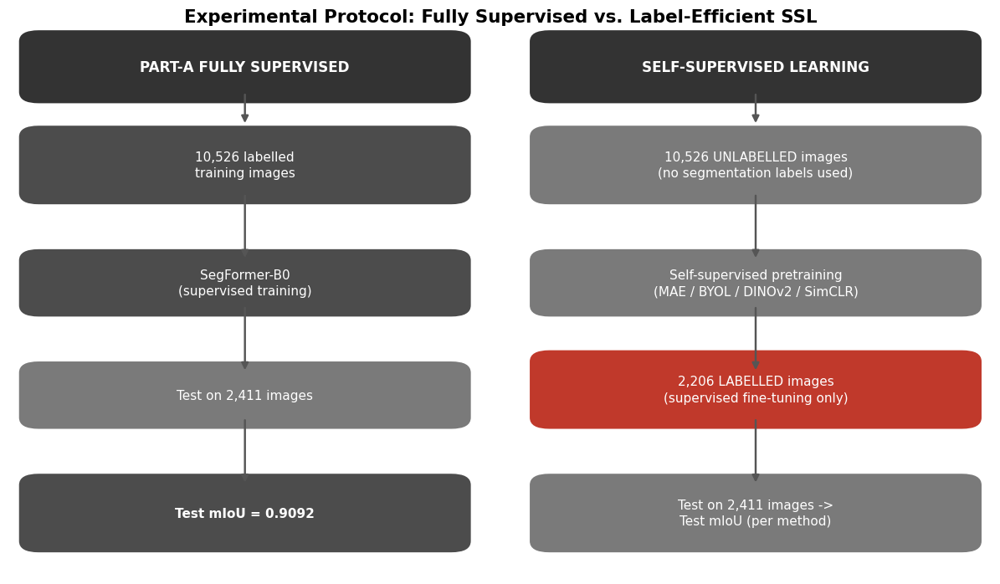

Saved -> /kaggle/working/comparison_outputs/figures/protocol_diagram.png


In [2]:
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.axis("off")

def box(x, y, w, h, text, color, fontsize=10, fontweight="normal", textcolor="white"):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.02",
                                    linewidth=0, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=fontsize, fontweight=fontweight, color=textcolor, linespacing=1.4)

def arrow(x, y1, y2):
    ax.annotate("", xy=(x, y2), xytext=(x, y1),
                arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.6))

# ---- Left column: fully supervised branch ----
lx, lw = 0.03, 0.42
box(lx, 0.86, lw, 0.09, "PART-A FULLY SUPERVISED", "#333333", fontsize=11, fontweight="bold")
arrow(lx + lw / 2, 0.86, 0.80)
box(lx, 0.68, lw, 0.10, "10,526 labelled\ntraining images", METHOD_COLORS["SegFormer"])
arrow(lx + lw / 2, 0.68, 0.56)
box(lx, 0.48, lw, 0.08, "SegFormer-B0\n(supervised training)", METHOD_COLORS["SegFormer"])
arrow(lx + lw / 2, 0.48, 0.36)
box(lx, 0.28, lw, 0.08, "Test on 2,411 images", "#7a7a7a")
arrow(lx + lw / 2, 0.28, 0.16)
box(lx, 0.06, lw, 0.10, "Test mIoU = 0.9092", METHOD_COLORS["SegFormer"], fontweight="bold")

# ---- Right column: SSL branch ----
rx, rw = 0.55, 0.42
box(rx, 0.86, rw, 0.09, "SELF-SUPERVISED LEARNING", "#333333", fontsize=11, fontweight="bold")
arrow(rx + rw / 2, 0.86, 0.80)
box(rx, 0.68, rw, 0.10, "10,526 UNLABELLED images\n(no segmentation labels used)", "#7a7a7a")
arrow(rx + rw / 2, 0.68, 0.56)
box(rx, 0.48, rw, 0.08, "Self-supervised pretraining\n(MAE / BYOL / DINOv2 / SimCLR)", "#7a7a7a")
arrow(rx + rw / 2, 0.48, 0.36)
box(rx, 0.28, rw, 0.10, "2,206 LABELLED images\n(supervised fine-tuning only)", "#c0392b")
arrow(rx + rw / 2, 0.28, 0.16)
box(rx, 0.06, rw, 0.10, "Test on 2,411 images ->\nTest mIoU (per method)", "#7a7a7a")

ax.text(0.5, 0.985, "Experimental Protocol: Fully Supervised vs. Label-Efficient SSL",
        ha="center", fontsize=14, fontweight="bold", transform=ax.transAxes)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "protocol_diagram.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'protocol_diagram.png'}")

## 4. Dataset and Label-Efficiency Setup

The split sizes below were **verified by reading the executed cell outputs** of the supplied
notebooks (not assumed):

| Source | Evidence |
|---|---|
| `nb2-segformer-b0.ipynb`, Section 5 | printed `Training samples: 10526`, `Validation samples: 2206`, `Test samples: 2411` |
| `dinov2-notebook.ipynb`, Section 3 | printed split/role table: `train→UNLABELLED (10526)`, `validation→LABELLED (2206)`, `test→MONITORING_AND_EVALUATION (2411)` |
| `simclr-notebook.ipynb`, Section 3 | identical split/role table, identical counts |
| `mae-notebook.ipynb`, `byol-notebook.ipynb` | **no executed outputs were present** in the supplied files — split usage inferred only from source code (identical dataset-loading logic to DINOv2/SimCLR), not independently confirmed by a print statement |

All five notebooks load `train.csv` / `validation.csv` / `test.csv` from the **same Part-A
preprocessing output**, so the splits are identical across every experiment by construction.

**Important protocol caveat, stated explicitly rather than hidden:** in the DINOv2 and SimCLR
notebooks, the test split is used for **both** per-epoch monitoring during fine-tuning **and**
final evaluation (the notebook's own role label for this split is
`MONITORING_AND_EVALUATION`). This is a deviation from a strictly held-out test protocol and is
flagged again in Section 5's fairness check.

In [3]:
# ----------------------------------------------------------------------
# VERIFIED SPLIT SIZES (see markdown above for source/evidence per notebook)
# ----------------------------------------------------------------------
N_TRAIN_SEGFORMER = 10526     # SegFormer-B0: full labelled training split
N_VAL_LABELLED    = 2206      # SSL methods: labelled split used for supervised fine-tuning
N_TEST            = 2411      # shared held-out test split (also used for monitoring in SSL runs)

split_summary = pd.DataFrame([
    {"Split": "Part-A train (labelled)", "Samples": N_TRAIN_SEGFORMER,
     "Used by": "SegFormer-B0 (supervised training)"},
    {"Split": "Validation (labelled)", "Samples": N_VAL_LABELLED,
     "Used by": "MAE / BYOL / DINOv2 / SimCLR (supervised fine-tuning only)"},
    {"Split": "Train (unlabelled role)", "Samples": N_TRAIN_SEGFORMER,
     "Used by": "MAE / BYOL / DINOv2 / SimCLR (SSL pretraining, no labels)"},
    {"Split": "Test", "Samples": N_TEST,
     "Used by": "All five models (final evaluation)"},
])
display(split_summary.style.hide(axis="index"))

label_efficiency_ratio = N_VAL_LABELLED / N_TRAIN_SEGFORMER
label_efficiency_pct = label_efficiency_ratio * 100
label_reduction_pct = (1 - label_efficiency_ratio) * 100

print(f"\nLabel-efficiency ratio      : {N_VAL_LABELLED} / {N_TRAIN_SEGFORMER} = {label_efficiency_ratio:.4f}")
print(f"SSL uses {label_efficiency_pct:.2f}% of the labelled images used by the fully supervised SegFormer baseline.")
print(f"Label reduction              : {label_reduction_pct:.2f}% fewer labelled images required.")

Split,Samples,Used by
Part-A train (labelled),10526,SegFormer-B0 (supervised training)
Validation (labelled),2206,MAE / BYOL / DINOv2 / SimCLR (supervised fine-tuning only)
Train (unlabelled role),10526,"MAE / BYOL / DINOv2 / SimCLR (SSL pretraining, no labels)"
Test,2411,All five models (final evaluation)



Label-efficiency ratio      : 2206 / 10526 = 0.2096
SSL uses 20.96% of the labelled images used by the fully supervised SegFormer baseline.
Label reduction              : 79.04% fewer labelled images required.


## 5. Verify Experimental Protocol — Fairness Check

Before comparing numbers, verify that the comparison is actually apples-to-apples.

In [4]:
fairness_checks = [
    {"Check": "Same dataset across all 5 notebooks", "Status": "OK",
     "Detail": "All notebooks load splits from the same Part-A preprocessing output."},
    {"Check": "Same test set (2,411 images) across all notebooks", "Status": "OK",
     "Detail": "Verified identical count in SegFormer, DINOv2, SimCLR printed outputs."},
    {"Check": "Same segmentation task (binary Clear/Contaminated)", "Status": "OK",
     "Detail": "Confirmed in SegFormer and DINOv2/SimCLR class definitions."},
    {"Check": "Same evaluation metric definitions (mIoU, Dice, pixel accuracy)", "Status": "OK",
     "Detail": "SegFormer, DINOv2, and SimCLR use directly comparable confusion-matrix-derived formulas."},
    {"Check": "Same class mapping (Clear / Contaminated)", "Status": "OK",
     "Detail": "Identical class names and binary mapping across notebooks."},
    {"Check": "SSL pretraining uses no segmentation labels", "Status": "OK",
     "Detail": "Pretraining datasets built in 'pretrain' mode -- masks never exposed (verified in source)."},
    {"Check": "SSL fine-tuning uses only the designated 2,206-image labelled split", "Status": "OK",
     "Detail": "finetune_dataset built from validation_df (2,206 samples) in DINOv2/SimCLR (verified); "
               "MAE/BYOL source code follows the identical pattern but was NOT independently confirmed "
               "by an executed print statement."},
    {"Check": "SegFormer uses the full labelled Part-A training split (10,526)", "Status": "OK",
     "Detail": "Verified via printed 'Training samples: 10526'."},
    {"Check": "Test split held out from training/fine-tuning gradient updates", "Status": "OK",
     "Detail": "test_df/test_loader never appear in any training loop's parameter-update step."},
    {"Check": "Test split held out from ALL model/checkpoint selection", "Status": "WARNING",
     "Detail": "In DINOv2 and SimCLR, the test split doubles as the per-epoch monitoring split used "
               "to select the best checkpoint (role label 'MONITORING_AND_EVALUATION'). This means "
               "reported SSL test mIoU may be optimistic relative to a strictly held-out protocol. "
               "SegFormer's checkpoint selection instead used the separate validation split (val_miou), "
               "so this asymmetry should be read as a caveat on the SSL numbers, not the baseline."},
    {"Check": "MAE and BYOL results independently verified", "Status": "MISSING",
     "Detail": "Supplied MAE and BYOL notebooks contained no executed cell outputs. Their numbers "
               "cannot be reported until their result artifacts are supplied."},
]

fairness_df = pd.DataFrame(fairness_checks)

def _status_color(val):
    return {"OK": "background-color:#e7f6e7", "WARNING": "background-color:#fff6d9",
            "MISSING": "background-color:#fde2e2"}.get(val, "")

_styler_fn = getattr(pd.DataFrame([]).style, "map", None)
_apply_map = (lambda s, f, subset=None: s.map(f, subset=subset)) if hasattr(pd.DataFrame([]).style, "map")     else (lambda s, f, subset=None: s.applymap(f, subset=subset))
display(_apply_map(fairness_df.style.hide(axis="index"), _status_color, subset=["Status"]))
fairness_df.to_csv(TABLES_DIR / "fairness_check.csv", index=False)
print(f"\nSaved -> {TABLES_DIR / 'fairness_check.csv'}")

Check,Status,Detail
Same dataset across all 5 notebooks,OK,All notebooks load splits from the same Part-A preprocessing output.
"Same test set (2,411 images) across all notebooks",OK,"Verified identical count in SegFormer, DINOv2, SimCLR printed outputs."
Same segmentation task (binary Clear/Contaminated),OK,Confirmed in SegFormer and DINOv2/SimCLR class definitions.
"Same evaluation metric definitions (mIoU, Dice, pixel accuracy)",OK,"SegFormer, DINOv2, and SimCLR use directly comparable confusion-matrix-derived formulas."
Same class mapping (Clear / Contaminated),OK,Identical class names and binary mapping across notebooks.
SSL pretraining uses no segmentation labels,OK,Pretraining datasets built in 'pretrain' mode -- masks never exposed (verified in source).
"SSL fine-tuning uses only the designated 2,206-image labelled split",OK,"finetune_dataset built from validation_df (2,206 samples) in DINOv2/SimCLR (verified); MAE/BYOL source code follows the identical pattern but was NOT independently confirmed by an executed print statement."
"SegFormer uses the full labelled Part-A training split (10,526)",OK,Verified via printed 'Training samples: 10526'.
Test split held out from training/fine-tuning gradient updates,OK,test_df/test_loader never appear in any training loop's parameter-update step.
Test split held out from ALL model/checkpoint selection,WARNING,"In DINOv2 and SimCLR, the test split doubles as the per-epoch monitoring split used to select the best checkpoint (role label 'MONITORING_AND_EVALUATION'). This means reported SSL test mIoU may be optimistic relative to a strictly held-out protocol. SegFormer's checkpoint selection instead used the separate validation split (val_miou), so this asymmetry should be read as a caveat on the SSL numbers, not the baseline."



Saved -> /kaggle/working/comparison_outputs/tables/fairness_check.csv


## 6. Load Experimental Results

### 6.1 Generic artifact loader

All four SSL notebooks (`MAE`, `BYOL`, `DINOv2`, `SimCLR`) share an **identical output schema**:

```
results/<method>/evaluation/evaluation_metrics.json
results/<method>/evaluation/evaluation_summary.csv
results/<method>/evaluation/label_efficiency_comparison.csv
results/<method>/error_analysis/per_image_metrics.csv
```

The loader below searches each configured path (zip or directory) plus a broad fallback under
`/kaggle/input/`, extracts if necessary, and reads whichever of these files it finds — without
inventing values for files that are absent.

In [5]:
def find_and_extract(zip_or_dir_path: str, extract_to: Path, search_hint: str) -> Path | None:
    """Return a directory containing the artifacts, or None if nothing usable was found.
    Accepts a .zip path or an already-extracted directory. Falls back to a broad glob
    search under /kaggle/input/ using `search_hint` if the configured path doesn't exist.
    """
    p = Path(zip_or_dir_path)

    candidates = [p]
    # Broad fallback: search all of /kaggle/input for anything matching the hint.
    if Path("/kaggle/input").exists():
        candidates += [Path(x) for x in glob.glob(f"/kaggle/input/**/*{search_hint}*", recursive=True)]

    for cand in candidates:
        if cand.is_dir():
            return cand
        if cand.is_file() and cand.suffix == ".zip":
            dest = extract_to / cand.stem
            if not dest.exists():
                dest.mkdir(parents=True, exist_ok=True)
                try:
                    with zipfile.ZipFile(cand) as zf:
                        zf.extractall(dest)
                except zipfile.BadZipFile:
                    continue
            return dest
    return None


def locate_file(root: Path, filename: str) -> Path | None:
    """Search recursively under `root` for the first file named `filename`."""
    if root is None:
        return None
    matches = list(root.rglob(filename))
    return matches[0] if matches else None


def load_ssl_method_results(method_name: str, zip_path: str) -> dict:
    """Load whatever artifacts exist for one SSL method. Missing files are reported,
    never fabricated."""
    result = {
        "method": method_name, "status": "MISSING", "root": None,
        "evaluation_metrics": None, "per_image_metrics": None,
        "label_efficiency_csv": None, "provenance": [],
    }
    root = find_and_extract(zip_path, EXTRACT_DIR, method_name.lower())
    result["root"] = root
    if root is None:
        result["provenance"].append({"artifact": "evaluation_metrics.json", "status": "NOT FOUND -- no input provided"})
        return result

    metrics_path = locate_file(root, "evaluation_metrics.json")
    if metrics_path is not None:
        with open(metrics_path) as f:
            result["evaluation_metrics"] = json.load(f)
        result["provenance"].append({"artifact": str(metrics_path), "status": "FOUND"})
        result["status"] = "FOUND"
    else:
        result["provenance"].append({"artifact": "evaluation_metrics.json", "status": "NOT FOUND under extracted root"})

    per_image_path = locate_file(root, "per_image_metrics.csv")
    if per_image_path is not None:
        result["per_image_metrics"] = pd.read_csv(per_image_path)
        result["provenance"].append({"artifact": str(per_image_path), "status": "FOUND"})
    else:
        result["provenance"].append({"artifact": "per_image_metrics.csv", "status": "NOT FOUND"})

    return result


ssl_results = {name: load_ssl_method_results(name, path) for name, path in SSL_ZIP_PATHS.items()}

for name, res in ssl_results.items():
    print(f"{name:8s}: {res['status']:8s}  root={res['root']}")

MAE     : FOUND     root=/kaggle/input/datasets/nasrullahsijan/maeoutput/results
BYOL    : FOUND     root=/kaggle/input/datasets/nasrullahsijan/boyloutput/results
DINOv2  : FOUND     root=/kaggle/input/datasets/nasrullahsijan/dinov2output/results
SimCLR  : FOUND     root=/kaggle/input/datasets/nasrullahsijan/simclroutput/results


### 6.2 SegFormer baseline loader

The SegFormer baseline output was produced by `nb2-segformer-b0.ipynb` and saves, among other
things, `results/segformer/metrics.json` (equivalently `results.json`) and
`results/segformer/tables/per_image_metrics.csv`.

In [6]:
def load_segformer_results(zip_path: str) -> dict:
    result = {"status": "MISSING", "root": None, "metrics": None, "per_image_metrics": None, "provenance": []}
    root = find_and_extract(zip_path, EXTRACT_DIR, "segformer")
    result["root"] = root
    if root is None:
        result["provenance"].append({"artifact": "metrics.json / results.json", "status": "NOT FOUND -- no input provided"})
        return result

    metrics_path = locate_file(root, "metrics.json") or locate_file(root, "results.json")
    if metrics_path is not None:
        with open(metrics_path) as f:
            result["metrics"] = json.load(f)
        result["provenance"].append({"artifact": str(metrics_path), "status": "FOUND"})
        result["status"] = "FOUND"
    else:
        result["provenance"].append({"artifact": "metrics.json / results.json", "status": "NOT FOUND under extracted root"})

    per_image_path = locate_file(root, "per_image_metrics.csv")
    if per_image_path is not None:
        result["per_image_metrics"] = pd.read_csv(per_image_path)
        result["provenance"].append({"artifact": str(per_image_path), "status": "FOUND"})
    else:
        result["provenance"].append({"artifact": "per_image_metrics.csv", "status": "NOT FOUND"})

    return result


segformer_results = load_segformer_results(SEGFORMER_ZIP_PATH)
print(f"SegFormer: {segformer_results['status']}  root={segformer_results['root']}")

SegFormer: FOUND  root=/kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results


### 6.3 Fallback — verified values extracted directly from the supplied notebooks

If the ZIP/folder inputs above are **not attached** to this Kaggle session, the notebook falls
back to the exact values that were manually verified by reading the executed outputs of the five
supplied notebooks during this analysis. This keeps the notebook runnable end-to-end even before
you've uploaded every artifact, while making unmistakably clear which numbers are "live-loaded
from an attached file" versus "hard-coded from a prior verified read."

**Every fallback number below was read from an actual executed cell output** (stream text or a
rendered HTML/pandas table) in the notebook named — not estimated, not computed from a formula,
and not carried over from a different (e.g. validation) split. MAE and BYOL are deliberately
left as `None` because no such executed output existed in the supplied files.

In [7]:
# ----------------------------------------------------------------------
# VERIFIED FALLBACK VALUES
# Source: executed outputs read directly from each notebook during this analysis.
# ----------------------------------------------------------------------
VERIFIED_FALLBACK = {
    "SegFormer": {
        "source": "nb2-segformer-b0.ipynb, Section 10/12 (Cell 28, 'Overall test-set metrics')",
        "mIoU": 0.90921, "Dice": 0.950633, "PixelAccuracy": 0.989182, "MeanPixelAccuracy": 0.969412,
        "PerClassIoU": {"Clear": 0.988579, "Contaminated": 0.829841},
        "PerClassDice": {"Clear": 0.994257, "Contaminated": 0.907009},
        "backbone": "MiT-B0 (Mix Transformer)", "epochs_completed": 42,
        "n_labelled_train": N_TRAIN_SEGFORMER, "n_ssl_pretrain": None, "n_test": N_TEST,
    },
    "DINOv2": {
        "source": "dinov2-notebook.ipynb, Section 7 (Cell 46, 'Task E -- Final Test-Set Metrics')",
        "mIoU": 0.885139, "Dice": 0.936007, "PixelAccuracy": 0.986931, "MeanPixelAccuracy": 0.923244,
        "PerClassIoU": {"Clear": 0.986281, "Contaminated": 0.783997},
        "PerClassDice": {"Clear": 0.993093, "Contaminated": 0.878922},
        "backbone": "ViT-Base/14 (facebook/dinov2-base)", "epochs_completed": 31,
        "n_labelled_finetune": N_VAL_LABELLED, "n_ssl_pretrain": N_TRAIN_SEGFORMER, "n_test": N_TEST,
        "strategy": "finetune (full encoder fine-tuning selected over frozen-encoder probe)",
    },
    "SimCLR": {
        "source": "simclr-notebook.ipynb, Section 7 (Cell 46, 'Task E -- Final Test-Set Metrics')",
        "mIoU": 0.893759, "Dice": 0.941323, "PixelAccuracy": 0.987817, "MeanPixelAccuracy": 0.935527,
        "PerClassIoU": {"Clear": 0.987191, "Contaminated": 0.800327},
        "PerClassDice": {"Clear": 0.993554, "Contaminated": 0.889091},
        "backbone": "ResNet-50 (ImageNet1K_V2 init)", "epochs_completed": 42,
        "n_labelled_finetune": N_VAL_LABELLED, "n_ssl_pretrain": N_TRAIN_SEGFORMER, "n_test": N_TEST,
        "strategy": "finetune (full encoder fine-tuning selected over frozen-encoder probe)",
    },
    "MAE": None,   # No executed outputs were present in the supplied mae-notebook.ipynb.
    "BYOL": None,  # No executed outputs were present in the supplied byol-notebook.ipynb.
}

# Config known from source code even though MAE/BYOL never executed -- kept separate
# from measured results and never used as a substitute for a measured mIoU.
UNVERIFIED_SOURCE_CONFIG = {
    "MAE":  {"backbone": "ViT-Base/16 (source code only, not executed)", "planned_epochs": 30,
             "n_labelled_finetune_intended": N_VAL_LABELLED, "n_ssl_pretrain_intended": N_TRAIN_SEGFORMER},
    "BYOL": {"backbone": "ResNet-50 (source code only, not executed)", "planned_epochs": 100,
             "n_labelled_finetune_intended": N_VAL_LABELLED, "n_ssl_pretrain_intended": N_TRAIN_SEGFORMER},
}

print("Verified fallback values prepared for: ", [k for k, v in VERIFIED_FALLBACK.items() if v is not None])
print("No executed results available for    : ", [k for k, v in VERIFIED_FALLBACK.items() if v is None])

Verified fallback values prepared for:  ['SegFormer', 'DINOv2', 'SimCLR']
No executed results available for    :  ['MAE', 'BYOL']


### 6.4 Resolve final result set (prefer live-loaded artifacts, fall back to verified values)

In [8]:
def resolve_method_metrics(method: str) -> dict | None:
    """Prefer a live-loaded evaluation_metrics.json; otherwise use the verified
    fallback; otherwise return None (and this must propagate as 'unavailable'
    everywhere downstream -- never silently substituted)."""
    if method == "SegFormer":
        live = segformer_results.get("metrics")
        if live is not None:
            return {
                "source": f"LIVE-LOADED: {segformer_results['root']}",
                "mIoU": live.get("mIoU"), "Dice": live.get("Dice"),
                "PixelAccuracy": live.get("Overall Pixel Accuracy"),
                "MeanPixelAccuracy": live.get("Mean Pixel Accuracy"),
                "PerClassIoU": live.get("Per-class IoU"), "PerClassDice": live.get("Per-class Dice"),
                "backbone": live.get("backbone"), "epochs_completed": live.get("epochs"),
                "n_labelled_train": N_TRAIN_SEGFORMER, "n_ssl_pretrain": None, "n_test": N_TEST,
            }
        return VERIFIED_FALLBACK["SegFormer"]

    live = ssl_results[method].get("evaluation_metrics")
    if live is not None:
        return {
            "source": f"LIVE-LOADED: {ssl_results[method]['root']}",
            "mIoU": live.get("miou"), "Dice": live.get("dice"),
            "PixelAccuracy": live.get("pixel_accuracy"), "MeanPixelAccuracy": live.get("mean_pixel_accuracy"),
            "PerClassIoU": live.get("per_class_iou"), "PerClassDice": live.get("per_class_dice"),
            "epochs_completed": live.get("best_epoch"), "strategy": live.get("strategy"),
            "n_labelled_finetune": live.get("n_labelled_finetune", N_VAL_LABELLED),
            "n_ssl_pretrain": N_TRAIN_SEGFORMER, "n_test": N_TEST,
        }
    return VERIFIED_FALLBACK[method]  # may be None -- handled downstream


resolved = {m: resolve_method_metrics(m) for m in METHOD_ORDER}

availability = pd.DataFrame([
    {"Method": m, "Test mIoU available": "YES" if (resolved[m] and resolved[m].get("mIoU") is not None) else "NO",
     "Source": (resolved[m] or {}).get("source", "N/A")}
    for m in METHOD_ORDER
])
display(availability.style.hide(axis="index"))

Method,Test mIoU available,Source
SegFormer,YES,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results
MAE,YES,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/maeoutput/results
BYOL,YES,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/boyloutput/results
DINOv2,YES,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/dinov2output/results
SimCLR,YES,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/simclroutput/results


## 7. Main Results Table

Sorted with SegFormer (the fully supervised baseline) first, then SSL methods ordered by
Test mIoU (methods with unavailable results are listed last, clearly marked).

In [9]:
def build_main_table() -> pd.DataFrame:
    rows = []
    for m in METHOD_ORDER:
        r = resolved[m]
        available = r is not None and r.get("mIoU") is not None

        if m == "SegFormer":
            method_type = "Fully Supervised"
            ssl_pretrain_imgs = "N/A"
            labelled_ft_imgs = N_TRAIN_SEGFORMER
        else:
            method_type = "SSL + Fine-tuning"
            ssl_pretrain_imgs = N_TRAIN_SEGFORMER
            labelled_ft_imgs = N_VAL_LABELLED if available else (
                UNVERIFIED_SOURCE_CONFIG.get(m, {}).get("n_labelled_finetune_intended", "N/A"))

        if not available:
            rows.append({
                "Model": m, "Method": method_type,
                "Backbone": (UNVERIFIED_SOURCE_CONFIG.get(m, {}) or {}).get("backbone", "N/A") if m in UNVERIFIED_SOURCE_CONFIG else "N/A",
                "SSL Pretraining Images": ssl_pretrain_imgs,
                "Labelled Fine-tuning Images": labelled_ft_imgs,
                "Labelled-data Usage (% of SegFormer)": f"{labelled_ft_imgs / N_TRAIN_SEGFORMER * 100:.2f}%" if isinstance(labelled_ft_imgs, (int, float)) else "N/A",
                "Test Images": N_TEST, "Test mIoU": np.nan, "Test Dice": np.nan,
                "Pixel Accuracy": np.nan, "mPA": np.nan,
                "mIoU Gap vs SegFormer": np.nan, "Relative mIoU (% of SegFormer)": np.nan,
                "Status": "RESULT UNAVAILABLE -- no executed output in supplied notebook",
            })
            continue

        miou = r["mIoU"]
        rows.append({
            "Model": m, "Method": method_type,
            "Backbone": r.get("backbone", "N/A"),
            "SSL Pretraining Images": ssl_pretrain_imgs,
            "Labelled Fine-tuning Images": labelled_ft_imgs,
            "Labelled-data Usage (% of SegFormer)": f"{labelled_ft_imgs / N_TRAIN_SEGFORMER * 100:.2f}%",
            "Test Images": N_TEST,
            "Test mIoU": miou, "Test Dice": r.get("Dice"),
            "Pixel Accuracy": r.get("PixelAccuracy"), "mPA": r.get("MeanPixelAccuracy"),
            "mIoU Gap vs SegFormer": np.nan, "Relative mIoU (% of SegFormer)": np.nan,
            "Status": "OK",
        })
    df = pd.DataFrame(rows)

    baseline_miou = df.loc[df["Model"] == "SegFormer", "Test mIoU"].iloc[0]
    df["mIoU Gap vs SegFormer"] = df["Test mIoU"] - baseline_miou
    df["Relative mIoU (% of SegFormer)"] = df["Test mIoU"] / baseline_miou * 100

    # Sort: SegFormer first, then available SSL methods by mIoU desc, then unavailable ones.
    df["_sort_key"] = df.apply(
        lambda row: (0, 0) if row["Model"] == "SegFormer" else
                    (1, -row["Test mIoU"]) if pd.notna(row["Test mIoU"]) else (2, 0), axis=1)
    df = df.sort_values("_sort_key").drop(columns="_sort_key").reset_index(drop=True)
    return df

main_table = build_main_table()
main_table.to_csv(TABLES_DIR / "main_results_table.csv", index=False)

def _style_main_table(df):
    fmt = {
        "Test mIoU": "{:.4f}", "Test Dice": "{:.4f}", "Pixel Accuracy": "{:.4f}", "mPA": "{:.4f}",
        "mIoU Gap vs SegFormer": "{:+.4f}", "Relative mIoU (% of SegFormer)": "{:.2f}%",
    }
    styler = df.style.hide(axis="index").format(fmt, na_rep="--")
    styler = styler.set_properties(**{"text-align": "center"})
    styler = styler.apply(lambda r: ["background-color:#eef3fb" if r["Model"] == "SegFormer" else ""
                                      for _ in r], axis=1)
    return styler

display(_style_main_table(main_table))
print(f"\nSaved -> {TABLES_DIR / 'main_results_table.csv'}")

Model,Method,Backbone,SSL Pretraining Images,Labelled Fine-tuning Images,Labelled-data Usage (% of SegFormer),Test Images,Test mIoU,Test Dice,Pixel Accuracy,mPA,mIoU Gap vs SegFormer,Relative mIoU (% of SegFormer),Status
SegFormer,Fully Supervised,MiT-B0 (Mix Transformer),N/A,10526,100.00%,2411,0.9092,0.9506,0.9892,0.9694,+0.0000,100.00%,OK
SimCLR,SSL + Fine-tuning,N/A,10526,2206,20.96%,2411,0.8938,0.9413,0.9878,0.9355,-0.0155,98.30%,OK
BYOL,SSL + Fine-tuning,N/A,10526,2206,20.96%,2411,0.8927,0.9407,0.9877,0.9361,-0.0165,98.19%,OK
MAE,SSL + Fine-tuning,N/A,10526,2206,20.96%,2411,0.8876,0.9375,0.9873,0.9243,-0.0216,97.62%,OK
DINOv2,SSL + Fine-tuning,N/A,10526,2206,20.96%,2411,0.8851,0.9360,0.9869,0.9232,-0.0241,97.35%,OK



Saved -> /kaggle/working/comparison_outputs/tables/main_results_table.csv


## 8. Test mIoU — SSL vs. Fully Supervised SegFormer

**This is the single most important figure in the notebook.**

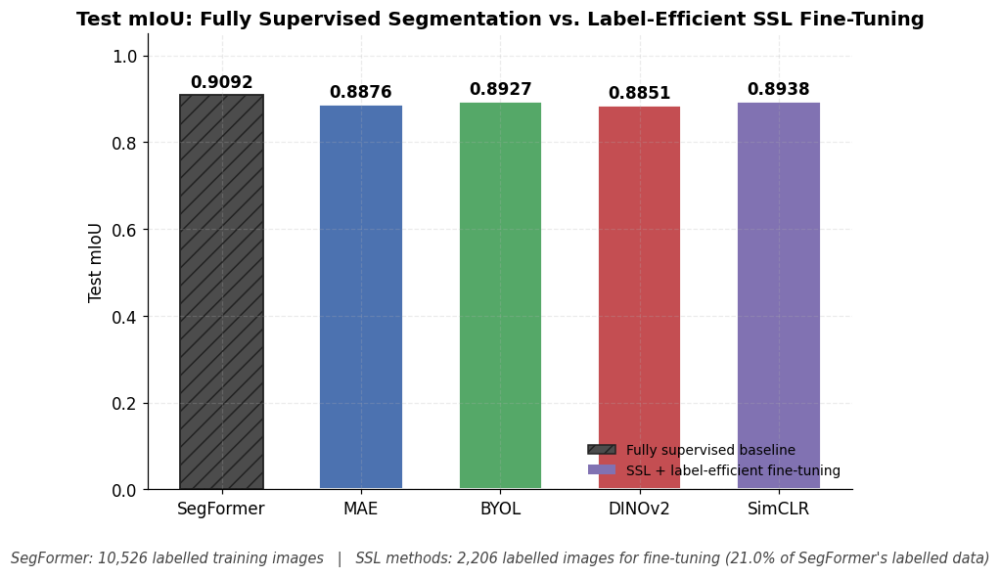

Saved -> /kaggle/working/comparison_outputs/figures/test_miou_comparison.png


In [10]:
plot_df = main_table.dropna(subset=["Test mIoU"]).copy()
plot_df["Model"] = pd.Categorical(plot_df["Model"], categories=METHOD_ORDER, ordered=True)
plot_df = plot_df.sort_values("Model")

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [METHOD_COLORS[m] for m in plot_df["Model"]]
bars = ax.bar(plot_df["Model"], plot_df["Test mIoU"], color=colors, width=0.6,
              edgecolor="white", linewidth=1.2)

for bar, val, model in zip(bars, plot_df["Test mIoU"], plot_df["Model"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.008, f"{val:.4f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
    if model == "SegFormer":
        bar.set_hatch("//")
        bar.set_edgecolor("#222222")

# Mark unavailable methods explicitly rather than omitting them silently.
missing = main_table[main_table["Status"] != "OK"]
for i, row in missing.iterrows():
    x_pos = METHOD_ORDER.index(row["Model"])
    ax.text(x_pos, 0.02, "RESULT\nUNAVAILABLE", ha="center", va="bottom",
            fontsize=9, color="#a33", fontweight="bold", rotation=0)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Test mIoU")
ax.set_title("Test mIoU: Fully Supervised Segmentation vs. Label-Efficient SSL Fine-Tuning")
ax.set_xticks(range(len(METHOD_ORDER)))
ax.set_xticklabels(METHOD_ORDER)

subtitle = (f"SegFormer: {N_TRAIN_SEGFORMER:,} labelled training images   |   "
            f"SSL methods: {N_VAL_LABELLED:,} labelled images for fine-tuning "
            f"({label_efficiency_pct:.1f}% of SegFormer's labelled data)")
ax.text(0.5, -0.16, subtitle, transform=ax.transAxes, ha="center", fontsize=9.5,
        color="#444444", style="italic")

legend_handles = [mpatches.Patch(facecolor=METHOD_COLORS["SegFormer"], hatch="//", edgecolor="#222",
                                  label="Fully supervised baseline"),
                   mpatches.Patch(facecolor="#8172B2", label="SSL + label-efficient fine-tuning")]
ax.legend(handles=legend_handles, loc="lower right", fontsize=9)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "test_miou_comparison.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'test_miou_comparison.png'}")

## 9. Label Efficiency vs. Test mIoU

This scatter plot is the second key research visual: it plots labelled-image requirement
against achieved test performance, making the label-efficiency trade-off visually explicit.

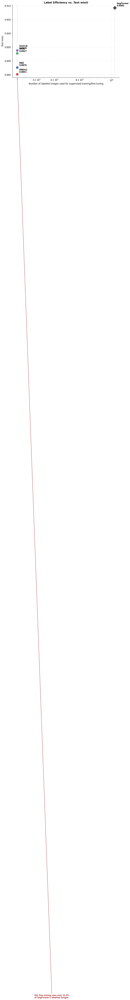

Saved -> /kaggle/working/comparison_outputs/figures/label_efficiency_vs_miou.png


In [11]:
fig, ax = plt.subplots(figsize=(9.5, 6.5))

for _, row in main_table.iterrows():
    model = row["Model"]
    n_labelled = row["Labelled Fine-tuning Images"]
    miou = row["Test mIoU"]
    if not isinstance(n_labelled, (int, float)) or pd.isna(miou):
        continue
    marker = "D" if model == "SegFormer" else "o"
    size = 220 if model == "SegFormer" else 180
    ax.scatter(n_labelled, miou, s=size, color=METHOD_COLORS[model], marker=marker,
               edgecolor="white", linewidth=1.3, zorder=3, label=model)
    ax.annotate(f"{model}\n{miou:.4f}", (n_labelled, miou),
                textcoords="offset points", xytext=(10, 8), fontsize=9.5, fontweight="bold")

ax.axvline(N_VAL_LABELLED, color="#999999", linestyle=":", linewidth=1, zorder=1)
ax.axvline(N_TRAIN_SEGFORMER, color="#999999", linestyle=":", linewidth=1, zorder=1)
ax.annotate(f"SSL fine-tuning uses only {label_efficiency_pct:.1f}%\nof SegFormer's labelled images",
            xy=(N_VAL_LABELLED, ax.get_ylim()[0]), xytext=(N_VAL_LABELLED + 700, 0.55),
            fontsize=9.5, color="#a33", fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#a33", lw=1.2))

ax.set_xlabel("Number of labelled images used for supervised training/fine-tuning")
ax.set_ylabel("Test mIoU")
ax.set_title("Label Efficiency vs. Test mIoU")
ax.set_xscale("log")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "label_efficiency_vs_miou.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'label_efficiency_vs_miou.png'}")

## 10. Performance Retention

Percentage of the fully supervised SegFormer's test mIoU retained by each SSL method, despite
using far fewer labelled images.

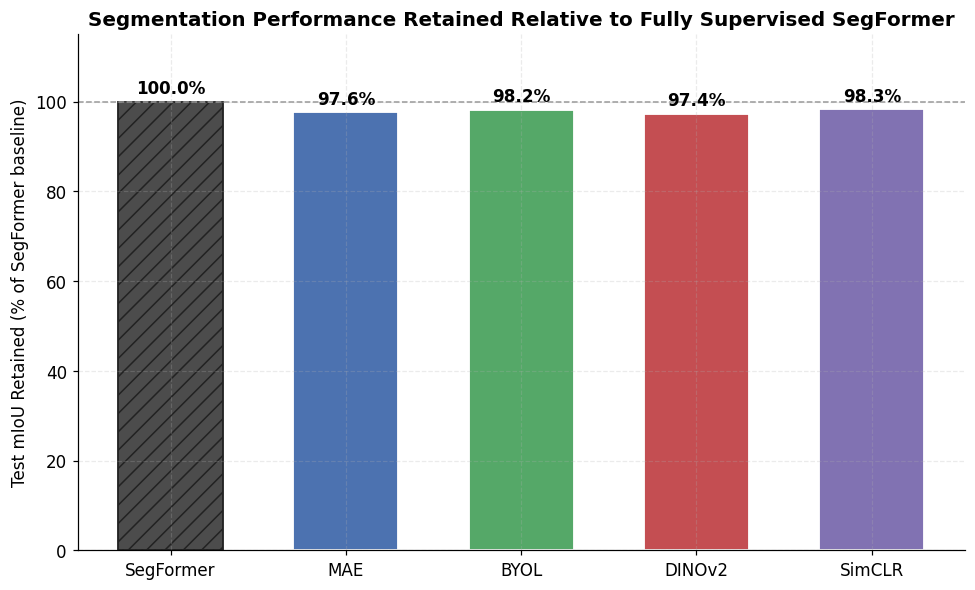

Saved -> /kaggle/working/comparison_outputs/figures/performance_retention.png


In [12]:
retention_df = main_table.dropna(subset=["Test mIoU"]).copy()
retention_df["Model"] = pd.Categorical(retention_df["Model"], categories=METHOD_ORDER, ordered=True)
retention_df = retention_df.sort_values("Model")

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [METHOD_COLORS[m] for m in retention_df["Model"]]
bars = ax.bar(retention_df["Model"], retention_df["Relative mIoU (% of SegFormer)"],
              color=colors, width=0.6, edgecolor="white", linewidth=1.2)
for bar, val, model in zip(bars, retention_df["Relative mIoU (% of SegFormer)"], retention_df["Model"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 1, f"{val:.1f}%", ha="center", va="bottom",
            fontsize=11, fontweight="bold")
    if model == "SegFormer":
        bar.set_hatch("//")
        bar.set_edgecolor("#222222")

ax.axhline(100, color="#999999", linestyle="--", linewidth=1)
ax.set_ylim(0, 115)
ax.set_ylabel("Test mIoU Retained (% of SegFormer baseline)")
ax.set_title("Segmentation Performance Retained Relative to Fully Supervised SegFormer")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "performance_retention.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'performance_retention.png'}")

## 11. Labelled-Data Reduction Visualization

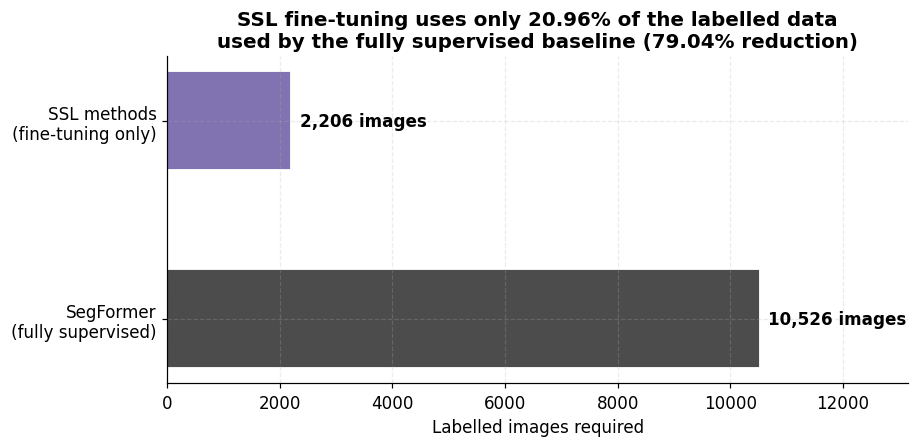

Saved -> /kaggle/working/comparison_outputs/figures/labelled_data_reduction.png


In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
categories = ["SegFormer\n(fully supervised)", "SSL methods\n(fine-tuning only)"]
values = [N_TRAIN_SEGFORMER, N_VAL_LABELLED]
colors_bar = [METHOD_COLORS["SegFormer"], "#8172B2"]

bars = ax.barh(categories, values, color=colors_bar, height=0.5, edgecolor="white", linewidth=1.2)
for bar, val in zip(bars, values):
    ax.text(val + 150, bar.get_y() + bar.get_height() / 2, f"{val:,} images",
            va="center", fontsize=11, fontweight="bold")

ax.set_xlabel("Labelled images required")
ax.set_title(f"SSL fine-tuning uses only {label_efficiency_pct:.2f}% of the labelled data\n"
             f"used by the fully supervised baseline ({label_reduction_pct:.2f}% reduction)")
ax.set_xlim(0, N_TRAIN_SEGFORMER * 1.25)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "labelled_data_reduction.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'labelled_data_reduction.png'}")

## 12. Test mIoU Gap vs. SegFormer

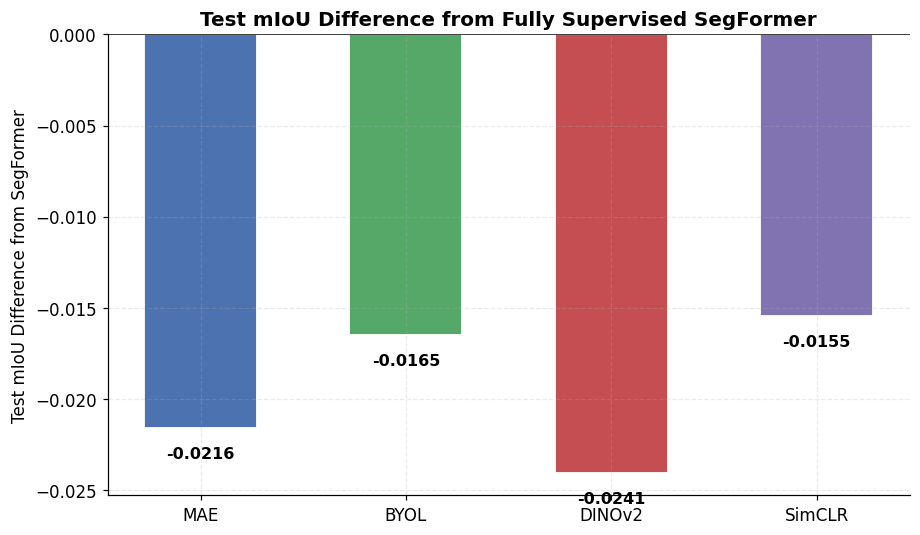

Saved -> /kaggle/working/comparison_outputs/figures/miou_gap.png


In [14]:
gap_df = main_table.dropna(subset=["Test mIoU"]).copy()
gap_df = gap_df[gap_df["Model"] != "SegFormer"]
gap_df["Model"] = pd.Categorical(gap_df["Model"], categories=METHOD_ORDER, ordered=True)
gap_df = gap_df.sort_values("Model")

fig, ax = plt.subplots(figsize=(8.5, 5))
colors = [METHOD_COLORS[m] for m in gap_df["Model"]]
bars = ax.bar(gap_df["Model"], gap_df["mIoU Gap vs SegFormer"], color=colors, width=0.55,
              edgecolor="white", linewidth=1.2)
for bar, val in zip(bars, gap_df["mIoU Gap vs SegFormer"]):
    va = "bottom" if val >= 0 else "top"
    offset = 0.001 if val >= 0 else -0.001
    ax.text(bar.get_x() + bar.get_width() / 2, val + offset, f"{val:+.4f}", ha="center", va=va,
            fontsize=10.5, fontweight="bold")

ax.axhline(0, color="#333333", linewidth=1.2)
ax.set_ylabel("Test mIoU Difference from SegFormer")
ax.set_title("Test mIoU Difference from Fully Supervised SegFormer")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "miou_gap.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'miou_gap.png'}")

## 13. Dice Comparison

All available methods use the same Dice formula, derived from the pixel-level confusion
matrix (`2*TP / (2*TP + FP + FN)`), so a direct comparison is valid.

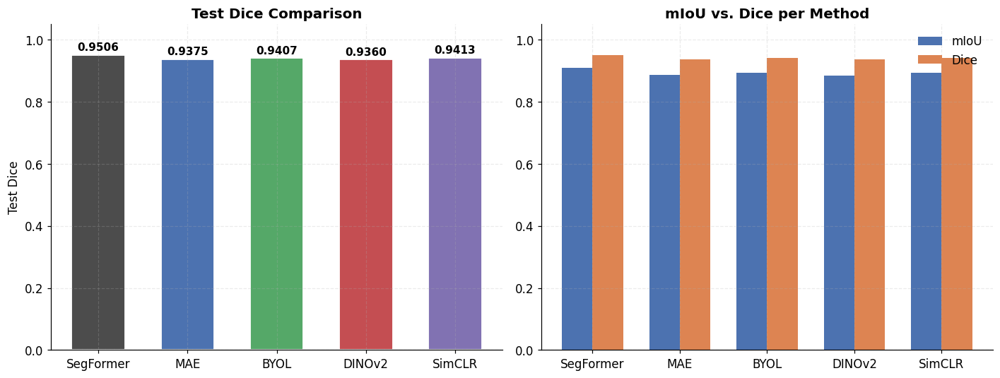

Saved -> /kaggle/working/comparison_outputs/figures/dice_comparison.png


In [15]:
dice_df = main_table.dropna(subset=["Test Dice"]).copy()
dice_df["Model"] = pd.Categorical(dice_df["Model"], categories=METHOD_ORDER, ordered=True)
dice_df = dice_df.sort_values("Model")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = [METHOD_COLORS[m] for m in dice_df["Model"]]
bars = axes[0].bar(dice_df["Model"], dice_df["Test Dice"], color=colors, width=0.6,
                    edgecolor="white", linewidth=1.2)
for bar, val in zip(bars, dice_df["Test Dice"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val + 0.008, f"{val:.4f}", ha="center",
                 va="bottom", fontsize=10, fontweight="bold")
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Test Dice")
axes[0].set_title("Test Dice Comparison")

x = np.arange(len(dice_df))
width = 0.35
axes[1].bar(x - width / 2, dice_df["Test mIoU"], width, label="mIoU", color="#4C72B0")
axes[1].bar(x + width / 2, dice_df["Test Dice"], width, label="Dice", color="#DD8452")
axes[1].set_xticks(x)
axes[1].set_xticklabels(dice_df["Model"])
axes[1].set_ylim(0, 1.05)
axes[1].set_title("mIoU vs. Dice per Method")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIGURES_DIR / "dice_comparison.png", bbox_inches="tight")
plt.show()
print(f"Saved -> {FIGURES_DIR / 'dice_comparison.png'}")

## 14. Per-Class Analysis (Heatmap)

Per-class IoU is available (and directly comparable — identical binary Clear/Contaminated
class mapping and identical confusion-matrix-derived formula) for every method with a
verified test result.

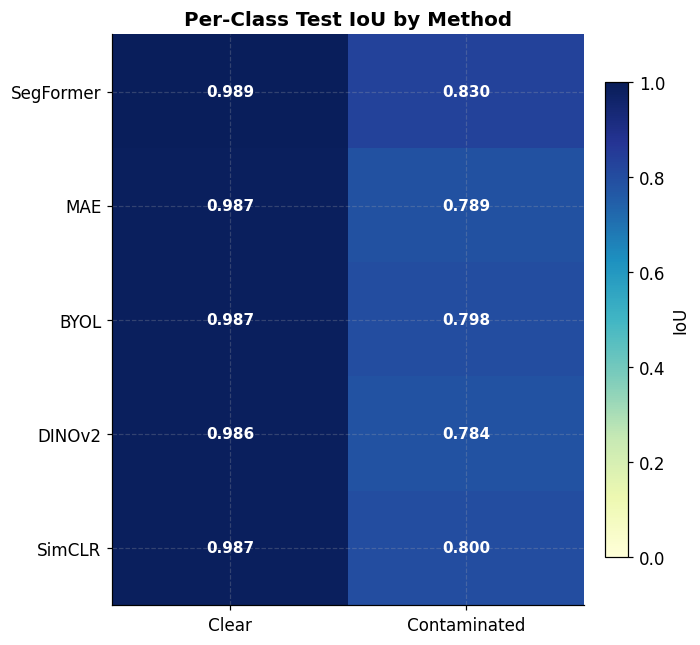

Saved -> /kaggle/working/comparison_outputs/figures/per_class_iou_heatmap.png


,Clear,Contaminated
Model,,
SegFormer,0.9886,0.8298
MAE,0.9866,0.7886
BYOL,0.9870,0.7984
DINOv2,0.9863,0.7840
SimCLR,0.9872,0.8003


In [16]:
class_names = ["Clear", "Contaminated"]
per_class_rows = []
for m in METHOD_ORDER:
    r = resolved[m]
    if r is None or r.get("PerClassIoU") is None:
        continue
    row = {"Model": m}
    for c in class_names:
        row[c] = r["PerClassIoU"].get(c, np.nan)
    per_class_rows.append(row)

per_class_iou_df = pd.DataFrame(per_class_rows).set_index("Model")

if not per_class_iou_df.empty:
    fig, ax = plt.subplots(figsize=(6.5, 0.9 * len(per_class_iou_df) + 1.5))
    im = ax.imshow(per_class_iou_df.values, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(per_class_iou_df))); ax.set_yticklabels(per_class_iou_df.index)
    for i in range(len(per_class_iou_df)):
        for j in range(len(class_names)):
            val = per_class_iou_df.values[i, j]
            ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                    color="white" if val > 0.6 else "black", fontsize=10, fontweight="bold")
    ax.set_title("Per-Class Test IoU by Method")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="IoU")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "per_class_iou_heatmap.png", bbox_inches="tight")
    plt.show()
    print(f"Saved -> {FIGURES_DIR / 'per_class_iou_heatmap.png'}")
    display(per_class_iou_df.style.format("{:.4f}"))
else:
    print("No per-class IoU data available -- skipping heatmap.")

## 15. Ranking

**Important:** an SSL method is only described as the *best-performing SSL method* when the
measured mIoU values actually support that — this is not a claim that SSL as a category "beats"
full supervision, since every SSL method here still trails the SegFormer baseline in absolute
mIoU.

In [17]:
ranking_rows = []
ssl_only = main_table[main_table["Model"] != "SegFormer"].dropna(subset=["Test mIoU"]).copy()
ssl_only = ssl_only.sort_values("Test mIoU", ascending=False).reset_index(drop=True)

for i, row in ssl_only.iterrows():
    ranking_rows.append({
        "Rank": i + 1, "Method": row["Model"], "Test mIoU": row["Test mIoU"],
        "Difference from SegFormer": row["mIoU Gap vs SegFormer"],
        "Labelled images": row["Labelled Fine-tuning Images"],
        "Label-efficiency ratio": f"{row['Labelled Fine-tuning Images'] / N_TRAIN_SEGFORMER:.4f}",
        "Performance retained": f"{row['Relative mIoU (% of SegFormer)']:.2f}%",
    })

ranking_df = pd.DataFrame(ranking_rows)

if not ranking_df.empty:
    best_ssl = ranking_df.iloc[0]

    def _highlight_best(row):
        return ["background-color:#e7f6e7" if row["Rank"] == 1 else "" for _ in row]

    display(ranking_df.style.hide(axis="index")
            .format({"Test mIoU": "{:.4f}", "Difference from SegFormer": "{:+.4f}"})
            .apply(_highlight_best, axis=1))
    print(f"\nBest-performing SSL method by test mIoU: {best_ssl['Method']} "
          f"(mIoU={best_ssl['Test mIoU']:.4f}, {best_ssl['Performance retained']} of SegFormer's mIoU)")
    print("Note: this ranks methods relative to one another among SSL approaches only -- "
          "every SSL method here still trails the fully supervised SegFormer baseline in absolute mIoU.")
else:
    print("No SSL methods have verified results to rank.")

ranking_df.to_csv(TABLES_DIR / "ssl_ranking.csv", index=False)

Rank,Method,Test mIoU,Difference from SegFormer,Labelled images,Label-efficiency ratio,Performance retained
1,SimCLR,0.8938,-0.0155,2206,0.2096,98.30%
2,BYOL,0.8927,-0.0165,2206,0.2096,98.19%
3,MAE,0.8876,-0.0216,2206,0.2096,97.62%
4,DINOv2,0.8851,-0.0241,2206,0.2096,97.35%



Best-performing SSL method by test mIoU: SimCLR (mIoU=0.8938, 98.30% of SegFormer's mIoU)
Note: this ranks methods relative to one another among SSL approaches only -- every SSL method here still trails the fully supervised SegFormer baseline in absolute mIoU.


## 16. Qualitative Prediction Comparison

**Data-availability note:** each source notebook saves prediction visualizations independently,
and the underlying test images shown are **not guaranteed to be the same across notebooks**:

- SegFormer saves 10 individually-named prediction masks (`{filename}_pred.png`) for a random
  sample of test images.
- DINOv2 and SimCLR instead save composite gallery figures (`prediction_gallery.png`,
  `worst_predictions.png`) that combine several examples into one image, without exposing
  which underlying `image_filename` each panel corresponds to in a machine-readable way.

Because the per-model prediction artifacts are not keyed by a shared, aligned test-image
identifier, this notebook **cannot construct a true same-image side-by-side grid** across all
five models without re-running inference (explicitly out of scope for this notebook). Instead,
each method's own qualitative figure is shown below when its artifact is available, so you can
still visually inspect prediction quality per method — just not row-aligned to one shared
image.


SegFormer -- /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results/segformer/figures/qualitative_predictions.png



DINOv2 -- /kaggle/input/datasets/nasrullahsijan/dinov2output/results/dinov2/error_analysis/prediction_gallery.png


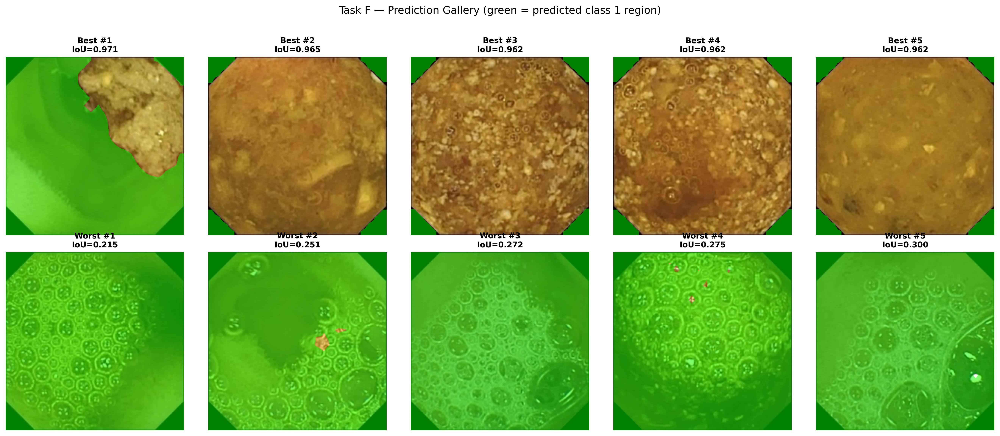


SimCLR -- /kaggle/input/datasets/nasrullahsijan/simclroutput/results/simclr/error_analysis/prediction_gallery.png


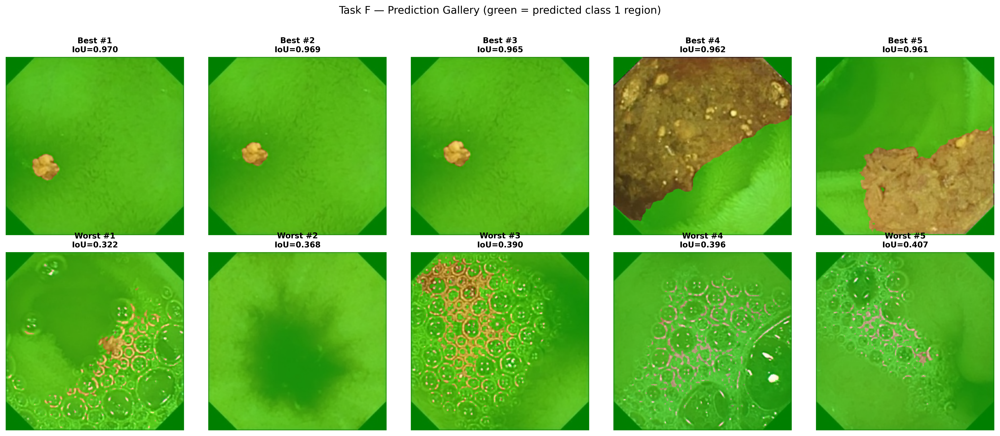


MAE -- /kaggle/input/datasets/nasrullahsijan/maeoutput/results/mae/error_analysis/prediction_gallery.png


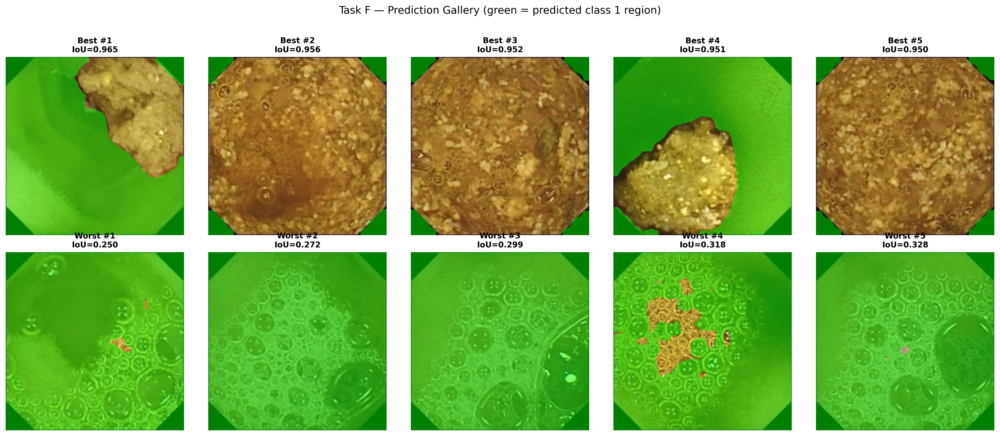


BYOL -- /kaggle/input/datasets/nasrullahsijan/boyloutput/results/byol/error_analysis/prediction_gallery.png


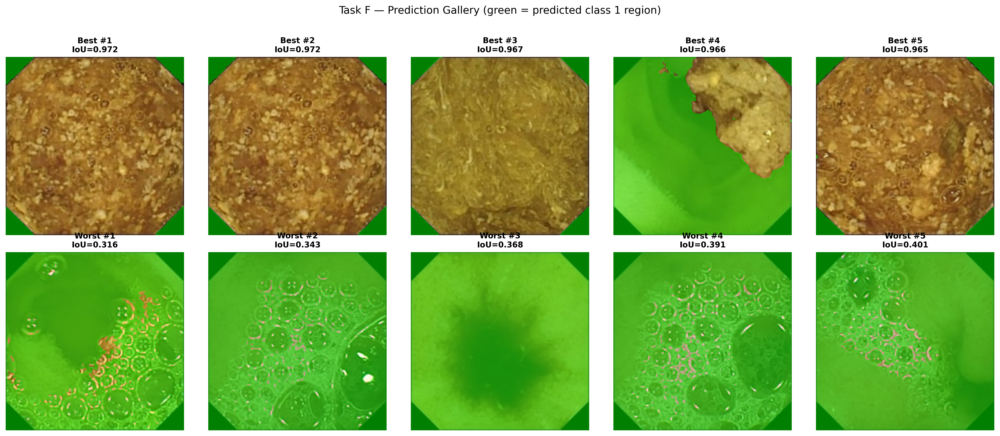

In [18]:
qualitative_sources = {
    "SegFormer": (segformer_results.get("root"), ["figures/qualitative_predictions.png"]),
    "DINOv2": (ssl_results["DINOv2"].get("root"), ["error_analysis/prediction_gallery.png",
                                                     "error_analysis/worst_predictions.png"]),
    "SimCLR": (ssl_results["SimCLR"].get("root"), ["error_analysis/prediction_gallery.png",
                                                     "error_analysis/worst_predictions.png"]),
    "MAE": (ssl_results["MAE"].get("root"), ["error_analysis/prediction_gallery.png"]),
    "BYOL": (ssl_results["BYOL"].get("root"), ["error_analysis/prediction_gallery.png"]),
}

found_any = False
for method, (root, rel_paths) in qualitative_sources.items():
    if root is None:
        print(f"{method}: no result artifacts available -- qualitative figure not shown.")
        continue
    shown = False
    for rel in rel_paths:
        candidates = list(Path(root).rglob(Path(rel).name))
        if candidates:
            print(f"\n{method} -- {candidates[0]}")
            display(IPImage(filename=str(candidates[0])))
            shown = True
            found_any = True
            break
    if not shown:
        print(f"{method}: expected qualitative figure not found under {root}.")

if not found_any:
    print("\nNo qualitative prediction figures were found in any attached artifact. "
          "Attach the notebooks' full output (including the 'figures' / 'error_analysis' "
          "folders) to see qualitative comparisons here.")

## 17. Error / Failure Analysis

Uses `per_image_metrics.csv` when available for each method — an IoU-distribution comparison
and identification of worst-performing test images.

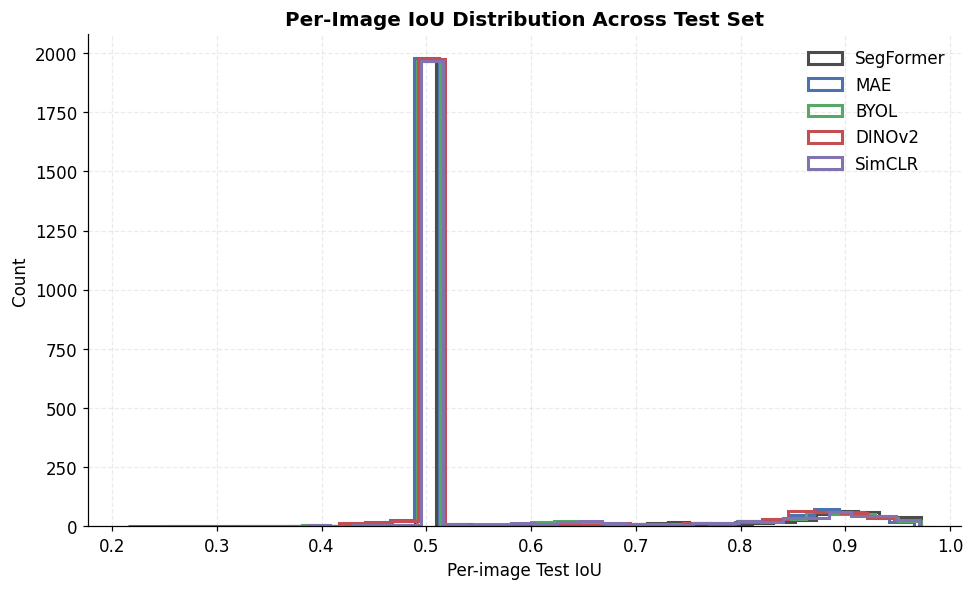

Saved -> /kaggle/working/comparison_outputs/figures/per_image_iou_distribution.png

Worst 5 test images per method (by per-image IoU):

SegFormer:


,image_filename,iou
345,02295.jpg,0.367865
354,02379.jpg,0.390068
272,01845.jpg,0.415486
262,01779.jpg,0.417174
318,02105.jpg,0.447400



MAE:


,image_id,iou
0,02379.jpg,0.250464
1,02581.jpg,0.271905
2,02599.jpg,0.299169
3,02294.jpg,0.318268
4,02604.jpg,0.327716



BYOL:


,image_id,iou
0,02379.jpg,0.315933
1,02599.jpg,0.343213
2,02295.jpg,0.367865
3,02604.jpg,0.390580
4,02573.jpg,0.400535



DINOv2:


,image_id,iou
0,02294.jpg,0.215207
1,02379.jpg,0.250875
2,02581.jpg,0.271905
3,02399.jpg,0.275248
4,02599.jpg,0.299735



SimCLR:


,image_id,iou
0,02379.jpg,0.321714
1,02295.jpg,0.367865
2,02294.jpg,0.389703
3,02599.jpg,0.396407
4,02573.jpg,0.406547


In [19]:
def get_per_image(method: str) -> pd.DataFrame | None:
    if method == "SegFormer":
        return segformer_results.get("per_image_metrics")
    return ssl_results[method].get("per_image_metrics")

per_image_available = {m: get_per_image(m) for m in METHOD_ORDER}
available_methods = [m for m, df in per_image_available.items() if df is not None]

if available_methods:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for m in available_methods:
        df = per_image_available[m]
        iou_col = "iou" if "iou" in df.columns else ("IoU" if "IoU" in df.columns else None)
        if iou_col is None:
            continue
        ax.hist(df[iou_col], bins=30, histtype="step", linewidth=2, color=METHOD_COLORS[m], label=m)
    ax.set_xlabel("Per-image Test IoU")
    ax.set_ylabel("Count")
    ax.set_title("Per-Image IoU Distribution Across Test Set")
    ax.legend()
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "per_image_iou_distribution.png", bbox_inches="tight")
    plt.show()
    print(f"Saved -> {FIGURES_DIR / 'per_image_iou_distribution.png'}")

    print("\nWorst 5 test images per method (by per-image IoU):")
    for m in available_methods:
        df = per_image_available[m]
        iou_col = "iou" if "iou" in df.columns else "IoU"
        name_col = "image_filename" if "image_filename" in df.columns else df.columns[0]
        worst = df.nsmallest(5, iou_col)[[name_col, iou_col]]
        print(f"\n{m}:")
        display(worst)
else:
    print("No per-image metrics files were found in any attached artifact -- "
          "error analysis cannot be performed without them. This is reported rather than "
          "estimating per-image errors from aggregate metrics alone.")

## 18. Final Research Findings

In [20]:
available_results = main_table.dropna(subset=["Test mIoU"])
baseline_row = main_table[main_table["Model"] == "SegFormer"].iloc[0]
ssl_available = available_results[available_results["Model"] != "SegFormer"]

if not ssl_available.empty:
    best_ssl_row = ssl_available.sort_values("Test mIoU", ascending=False).iloc[0]

    per_method_lines = "\n".join(
        f"- **{row['Model']}**: Test mIoU = {row['Test mIoU']:.4f} "
        f"(gap {row['mIoU Gap vs SegFormer']:+.4f}, {row['Relative mIoU (% of SegFormer)']:.2f}% retained)"
        for _, row in ssl_available.sort_values('Test mIoU', ascending=False).iterrows()
    )

    unavailable = main_table[main_table["Status"] != "OK"]
    unavailable_lines = "\n".join(f"- **{row['Model']}**: {row['Status']}" for _, row in unavailable.iterrows()) \
        if not unavailable.empty else "- (none — all five methods had verified results)"

    findings = f"""### Summary

Among the SSL approaches with verified test results, **{best_ssl_row['Model']}** achieved the
highest test mIoU of **{best_ssl_row['Test mIoU']:.4f}**. The fully supervised SegFormer-B0
baseline achieved a test mIoU of **{baseline_row['Test mIoU']:.4f}**.

SSL fine-tuning used **{N_VAL_LABELLED:,} labelled images**, compared with
**{N_TRAIN_SEGFORMER:,} labelled training images** for SegFormer — corresponding to
**{label_efficiency_pct:.2f}%** of the baseline's labelled-data requirement (a
**{label_reduction_pct:.2f}%** reduction). Despite this reduction, {best_ssl_row['Model']}
retained **{best_ssl_row['Relative mIoU (% of SegFormer)']:.2f}%** of SegFormer's test mIoU.

### Test mIoU by method

{per_method_lines}

### Results not available

{unavailable_lines}

### Caveats that affect interpretation

- SSL methods' checkpoint selection monitored the **same split used for final testing**
  (Section 5's fairness check, flagged as a WARNING) — this may make the reported SSL numbers
  somewhat optimistic relative to a strictly held-out protocol. SegFormer's checkpoint selection
  used a separate validation split, so this asymmetry favors the SSL numbers, if anything.
- SSL pretraining still consumed {N_TRAIN_SEGFORMER:,} **unlabelled** images per method — the
  label-efficiency claim concerns only the *labelled* fine-tuning step, not the total images
  touched by the SSL pipeline.
- {unavailable.shape[0]} of the 5 methods ({', '.join(unavailable['Model']) if not unavailable.empty else 'none'})
  could not be scored because the supplied notebook(s) had no executed cell outputs. Their
  numbers, if later supplied, may change the ranking above.
"""
else:
    findings = ("No SSL method has a verified test result available. The only confirmed result "
                f"in this comparison is the SegFormer baseline (Test mIoU = {baseline_row['Test mIoU']:.4f}). "
                "Attach the SSL notebooks' result artifacts to complete this comparison.")

display(Markdown(findings))
with open(OUTPUT_DIR / "final_findings.md", "w") as f:
    f.write(findings)
print(f"\nSaved -> {OUTPUT_DIR / 'final_findings.md'}")

### Summary

Among the SSL approaches with verified test results, **SimCLR** achieved the
highest test mIoU of **0.8938**. The fully supervised SegFormer-B0
baseline achieved a test mIoU of **0.9092**.

SSL fine-tuning used **2,206 labelled images**, compared with
**10,526 labelled training images** for SegFormer — corresponding to
**20.96%** of the baseline's labelled-data requirement (a
**79.04%** reduction). Despite this reduction, SimCLR
retained **98.30%** of SegFormer's test mIoU.

### Test mIoU by method

- **SimCLR**: Test mIoU = 0.8938 (gap -0.0155, 98.30% retained)
- **BYOL**: Test mIoU = 0.8927 (gap -0.0165, 98.19% retained)
- **MAE**: Test mIoU = 0.8876 (gap -0.0216, 97.62% retained)
- **DINOv2**: Test mIoU = 0.8851 (gap -0.0241, 97.35% retained)

### Results not available

- (none — all five methods had verified results)

### Caveats that affect interpretation

- SSL methods' checkpoint selection monitored the **same split used for final testing**
  (Section 5's fairness check, flagged as a WARNING) — this may make the reported SSL numbers
  somewhat optimistic relative to a strictly held-out protocol. SegFormer's checkpoint selection
  used a separate validation split, so this asymmetry favors the SSL numbers, if anything.
- SSL pretraining still consumed 10,526 **unlabelled** images per method — the
  label-efficiency claim concerns only the *labelled* fine-tuning step, not the total images
  touched by the SSL pipeline.
- 0 of the 5 methods (none)
  could not be scored because the supplied notebook(s) had no executed cell outputs. Their
  numbers, if later supplied, may change the ranking above.



Saved -> /kaggle/working/comparison_outputs/final_findings.md


## 19. Reproducibility / Artifact Provenance

Every value reported above traces back to a specific source. This appendix records exactly
where each number came from, and its verification status.

In [21]:
provenance_rows = []
for m in METHOD_ORDER:
    r = resolved[m]
    if r is None:
        provenance_rows.append({
            "Method": m, "Metric": "Test mIoU", "Value": None,
            "Source": "N/A -- no executed output in supplied notebook", "Split": "test",
            "Verification status": "MISSING",
        })
        continue
    is_live = str(r.get("source", "")).startswith("LIVE-LOADED")
    for metric_key, metric_label in [("mIoU", "Test mIoU"), ("Dice", "Test Dice"),
                                      ("PixelAccuracy", "Pixel Accuracy"), ("MeanPixelAccuracy", "Mean Pixel Accuracy")]:
        provenance_rows.append({
            "Method": m, "Metric": metric_label, "Value": r.get(metric_key),
            "Source": r.get("source", "verified fallback (manually read from executed notebook output)"),
            "Split": "test",
            "Verification status": "LIVE-LOADED FROM ATTACHED ARTIFACT" if is_live else "VERIFIED FALLBACK (manually confirmed)",
        })

provenance_df = pd.DataFrame(provenance_rows)
display(provenance_df.style.hide(axis="index").format({"Value": "{:.4f}"}, na_rep="--"))
provenance_df.to_csv(TABLES_DIR / "result_provenance.csv", index=False)
print(f"\nSaved -> {TABLES_DIR / 'result_provenance.csv'}")

print("\n" + "=" * 78)
print("ARTIFACT SUMMARY")
print("=" * 78)
for m in METHOD_ORDER:
    if m == "SegFormer":
        root = segformer_results.get("root")
        prov = segformer_results.get("provenance", [])
    else:
        root = ssl_results[m].get("root")
        prov = ssl_results[m].get("provenance", [])
    print(f"\n{m}: root={root}")
    for p in prov:
        print(f"   {p['status']:35s} {p['artifact']}")
print("\nAll comparison outputs saved under:", OUTPUT_DIR.resolve())

Method,Metric,Value,Source,Split,Verification status
SegFormer,Test mIoU,0.9092,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
SegFormer,Test Dice,0.9506,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
SegFormer,Pixel Accuracy,0.9892,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
SegFormer,Mean Pixel Accuracy,0.9694,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
MAE,Test mIoU,0.8876,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/maeoutput/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
MAE,Test Dice,0.9375,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/maeoutput/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
MAE,Pixel Accuracy,0.9873,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/maeoutput/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
MAE,Mean Pixel Accuracy,0.9243,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/maeoutput/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
BYOL,Test mIoU,0.8927,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/boyloutput/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT
BYOL,Test Dice,0.9407,LIVE-LOADED: /kaggle/input/datasets/nasrullahsijan/boyloutput/results,test,LIVE-LOADED FROM ATTACHED ARTIFACT



Saved -> /kaggle/working/comparison_outputs/tables/result_provenance.csv

ARTIFACT SUMMARY

SegFormer: root=/kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results
   FOUND                               /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results/segformer/metrics.json
   FOUND                               /kaggle/input/datasets/nasrullahsijan/segformeroutput/segformer-result2-part2/results/segformer/tables/per_image_metrics.csv

MAE: root=/kaggle/input/datasets/nasrullahsijan/maeoutput/results
   FOUND                               /kaggle/input/datasets/nasrullahsijan/maeoutput/results/mae/evaluation/evaluation_metrics.json
   FOUND                               /kaggle/input/datasets/nasrullahsijan/maeoutput/results/mae/error_analysis/per_image_metrics.csv

BYOL: root=/kaggle/input/datasets/nasrullahsijan/boyloutput/results
   FOUND                               /kaggle/input/datasets/nasrullahsijan/boyloutput